In [2]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

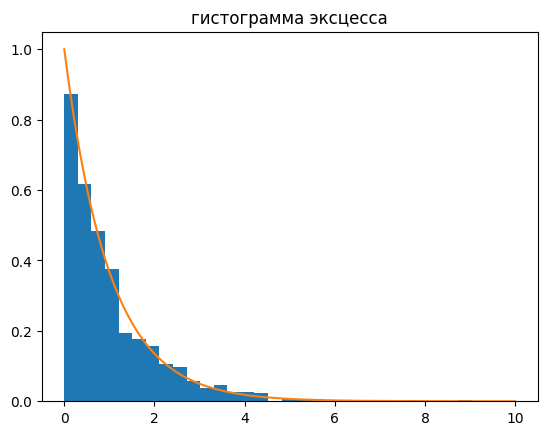

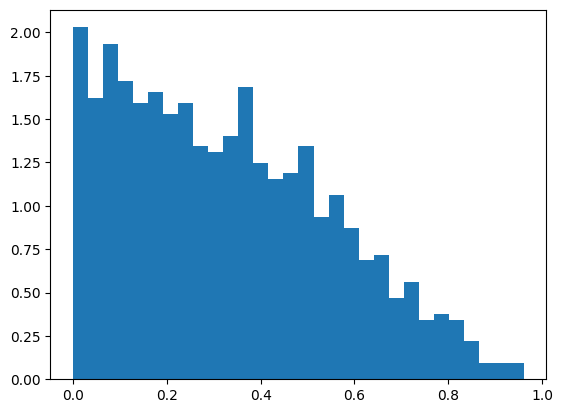

In [24]:
def excess(s, t):
    c = 0
    while s[c] < t and c<n-1:
        c+=1
    return (s[c] - t)

def renewal_process_exp(n, lmbd): # n - число скачков
    x = np.random.exponential(lmbd, size = n-1)
    S = [np.sum(x[:k:]) for k in range(n)]
    return S

def renewal_process_uni(n): # n - число скачков
    x = np.random.uniform(0, 1, size = n-1)
    S = [np.sum(x[:k:]) for k in range(n)]
    return S

n = 3000 #длина процесса
m = 1000 # выборка эксцессов
t = 2000
lmbd = 1
ex = []

for k in range(m):
    s = renewal_process_exp(n, lmbd)
    ex.append(excess(s, t))
plt.hist(ex, density="true", bins = 30)
l = np.linspace(0,10,1000)
plt.plot(l,sc.stats.expon.pdf(l,scale = lmbd))
plt.title("гистограмма эксцесса")
plt.show()

ex2 = []
t = 1000
for k in range(m):
    s = renewal_process_uni(n)
    ex2.append(excess(s, t))
plt.hist(ex2, density="true", bins = 30)
l = np.linspace(0,10,1000)

In [ ]:
2. Исследовать парадокс времени ожидания: моделировать а) пуассоновский поток с λ = 2 б) процесс с
Gamma(2, 1/4) распределением между скачками в) процесс с R[0, 1] распределением между скачками.
Рассмотреть среднюю длину промежутка, накрывающего момент 100 и соотнести с математическим
ожиданием между промежутками.

In [13]:
def renewal_process_exp(n, lmbd): # n - число скачков
    x = np.random.exponential(scale = 1/lmbd, size = n-1)
    S = [np.sum(x[:k:]) for k in range(n)]
    return S

def renewal_process_uni(n): # n - число скачков
    x = np.random.uniform(0, 1, size = n-1)
    S = [np.sum(x[:k:]) for k in range(n)]
    return S

def renewal_process_gamma(a, b, n): # n - число скачков
    x = np.random.gamma(shape = a, scale = b, size = n-1)
    S = [np.sum(x[:k:]) for k in range(n)]
    return S
    
n = 500 #длина процесса
m = 1000 # выборка длин промежутков, накрывающих 100
lengths = [0]*m
t = 100

for k in range(m):
    s = renewal_process_exp(n, lmbd = 2)
    for l in range(n):
        if s[l] > 100:
            lengths[k] = s[l] - s[l-1]
            break
print("exp(1/2) шаги")
print("средняя длина:", np.mean(lengths), " среднее шага:", 1/2)


lengths = [0]*m
for k in range(m):
    s = renewal_process_uni(n)
    for l in range(n):
        if s[l] > 100:
            lengths[k] = s[l] - s[l-1]
            break
print("R[0,1] шаги")
print("средняя длина:", np.mean(lengths), " среднее шага:", 1/2)


lengths = [0]*m
for k in range(m):
    s = renewal_process_gamma(a = 2, b = 1/4, n = n)
    for l in range(n):
        if s[l] > 100:
            lengths[k] = s[l] - s[l-1]
            break
print("Gamma(2,1/4) шаги")
print("средняя длина:", np.mean(lengths), " среднее шага:", 1/2)

exp(1/2) шаги
средняя длина: 1.0289196865593813  среднее шага: 0.5
R[0,1] шаги
средняя длина: 0.678332852016913  среднее шага: 0.5
Gamma(2,1/4) шаги
средняя длина: 0.7471559161101372  среднее шага: 0.5


In [ ]:
3. Исследуем условное свойство пуассоновского потока. Сгенерируйте точки пуассоновского потока а) на
прямой б*) на плоскости и проверьте точки, попавшие на а) отрезок б*) квадрат на равномерность.

In [32]:
def renewal_process_exp(n, lmbd): # n - число скачков
    x = np.random.exponential(scale = 1/lmbd, size = n-1)
    S = [np.sum(x[:k:]) for k in range(n)]
    return S

def F_0(x):
    return sc.stats.uniform.cdf(x, 8, 10)
    
def ad_stat(n,x):
    y = np.sort(x)
    return(-n - np.sum([ (2*i-1)/(n) * (np.log(F_0(y[i-1]))+np.log(1-F_0(y[n-i])) ) for i in range(1,n+1)]))

def poiss_plane(n):
    M = 500 # шаг круговой сетки
    r = [0]*n
    phi = np.random.uniform(0, 2*np.pi, size = n)
    count = 0 
    k = 0
    radius = np.pi*(1/M)**2
    while count != n:
        k+=1
        if np.random.binomial(1, np.exp((-1)*(2*k-1)*np.pi *(1/M)**2)) == 0:
            r[count] = k*np.pi*(1/M)**2
            count += 1
    return r, phi
"""         
ad_loaded = np.loadtxt('ad_values.txt')

n = 500 #длина процесса
a, b = 8, 18 # отрезок. важно что у меня в статистике уже 8 и 18,  их лучше не менять

s = renewal_process_exp(n, lmbd = 1)
x = [s[l] for l in range(n) if s[l]<=b and s[l]>= a] 

print("pvalue ad:", 1 - sc.stats.ecdf(ad_loaded).cdf.evaluate(ad_stat(len(x), x)))
"""
n = 10000
r, phi = poiss_plane(n)
x = np.array([r[j]*np.cos(j) for j in range(n)])
y = np.array([r[j]*np.sin(j) for j in range(n)])
#plt.scatter(x,y)
print(hyp.independence.Dcorr().test(x,y)[1])

1.9672612925562486e-11


In [ ]:
5. * Воспользуемся условным свойством неоднородного пуассоновского потока для моделирования выбор-
ки с заданной плотностью. Создать генератор выбороки случайного размера из а) распределения с

плотностью sin x на [0, π] б) треугольной плотностью x на [0,1], 2 − x на [1, 2]. Построить гистограммы

и убедиться в том, что плотность получилась требуемой. Для моделирования потока с заданной интен-
сивностью просто ждите небольшое время dt и разыгрывайте попала ли точка потока на него исходя из

вероятности λ(t)dt. Увеличивайте λ(x) в константу раз, чтобы делать выборку большего или меньшего
размера.

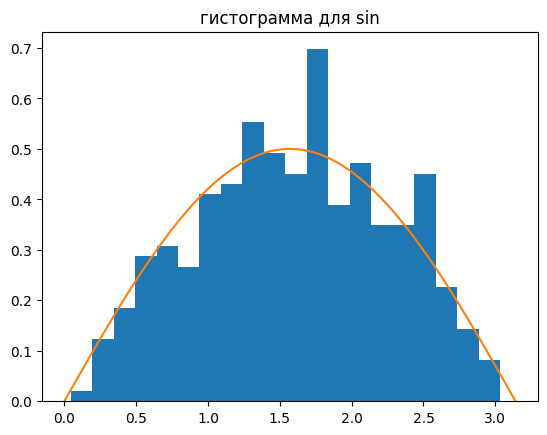

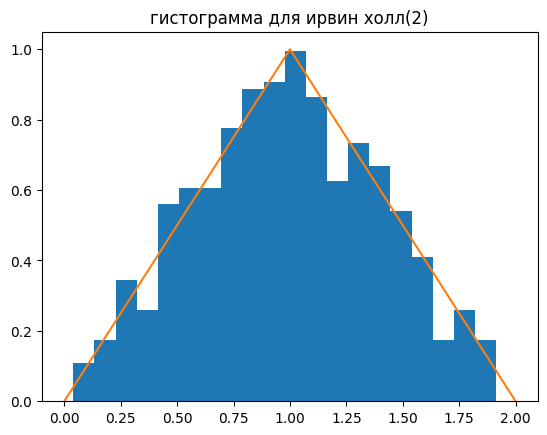

In [39]:
def generator(m, c, f, supp): # интенсивность = с*плотность, m - дискретизация, f - плотность
    a, b = supp[0], supp[1]
    l = [ a + b*k/m for k in range(m* int(b-a))]
    x = []
    for k in range(m * int(b-a)):
        if np.random.binomial(1, 1/m * c * f(l[k])) == 1:
            x.append(l[k])
    return x

def f_a(x):
    if x<= 0 or x >= np.pi:
        return 0
    else:
        return np.sin(x)/2

def f_b(x):
    if x>=0 and x<= 1:
        return x
    if x >= 1 and x <= 2:
        return 2 - x
    else:
        return 0

c = 1000 # умножа. на это интенсивность
m = 1000 # дискретизация

x = generator(m, c, f_a, [0,np.pi])
#print(x)

l = [np.pi*k/m for k in range(m)]
plt.hist(x, density = "true", bins = 20)
plt.title("гистограмма для sin")
plt.plot(l, np.sin(l)/2)
plt.show()

x = generator(m, c, f_b, [0, 2])
#print(x)

l = [2*k/m for k in range(m)]
plt.hist(x, density = "true", bins = 20)
plt.title("гистограмма для ирвин холл(2)")
plt.plot(l, [f_b(x) for x in l])
plt.show()

In [25]:
df=pd.read_csv("COAL MINING DISASTERS.csv", sep = ";", encoding="cp1251")
x = df["Count"].values
x1 = x[:56:]
x2 = x[56:111:]
print(sc.stats.anderson_ksamp([x1, x2], variant = "midrank").pvalue)

0.001


C:\Users\MI\AppData\Local\Temp\ipykernel_6256\2555248055.py:5: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(sc.stats.anderson_ksamp([x1, x2], variant = "midrank").pvalue)
